## <span style="color: #a855f7">CNN training stability</span>

<span style="color: #a855f7">порівняння вихідної CNN та версії з BatchNorm, Dropout і контролем градієнтів на MNIST, обидві моделі навчаються 10 епох на всій train-вибірці, тестові метрики обчислюються після навчання</span>

In [1]:
import os
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import HTML, display
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

RANDOM_STATE = 42
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001
CPU_THREADS = min(4, os.cpu_count() or 1)
DATA_ROOT = Path("data")
MAX_GRAD_NORM = 1.0
DROPOUT = 0.3
LOSS_PLOT_PATH = Path("cnn_training_comparison.png")
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]

torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(CPU_THREADS)


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<p style="color: #a855f7; margin: 12px 0 6px">{escape(str(value))}</p>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})


## <span style="color: #a855f7">MNIST data</span>

<span style="color: #a855f7">60000 train і 10000 test зображень 28×28, ToTensor і Normalize з mean=0.5 та std=0.5 переводять пікселі у шкалу [-1, 1], batch_size=64, train перемішується, test має фіксований порядок, всі файли MNIST зберігаються в data, перше завантаження потребує інтернету</span>

In [2]:
class FlatMNIST(datasets.MNIST):
    @property
    def raw_folder(self) -> str:
        return os.fspath(self.root)


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
train_dataset = FlatMNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_dataset = FlatMNIST(DATA_ROOT, train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "images": [len(train_dataset), len(test_dataset)],
    "batch size": [BATCH_SIZE, BATCH_SIZE],
    "image shape": [str(tuple(train_dataset[0][0].shape)), str(tuple(test_dataset[0][0].shape))],
}), index=False)


split,images,batch size,image shape
train,60000,64,"(1, 28, 28)"
test,10000,64,"(1, 28, 28)"


## <span style="color: #a855f7">Baseline and regularized CNN</span>

<span style="color: #a855f7">вихідна модель: Conv2d(1, 16, 3) → ReLU → MaxPool2d(2) → Flatten → Linear(2704, 10), друга модель додає BatchNorm2d(16) після єдиного Conv2d та Dropout(p=0.3) одразу після ReLU, dropout вимикається під час оцінювання, BatchNorm використовує накопичені train-статистики, CrossEntropyLoss працює з logits без окремого Softmax</span>

In [3]:
def create_model(regularized=False):
    layers: list[nn.Module] = [nn.Conv2d(1, 16, kernel_size=3)]
    if regularized:
        layers.append(nn.BatchNorm2d(16))
    layers.append(nn.ReLU())
    if regularized:
        layers.append(nn.Dropout(p=DROPOUT))
    layers.extend([
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 13 * 13, 10),
    ])
    return nn.Sequential(*layers)


architectures = []
for name, regularized in [("Baseline", False), ("BatchNorm + Dropout", True)]:
    torch.manual_seed(RANDOM_STATE)
    network = create_model(regularized)
    architectures.append({
        "configuration": name,
        "layers": " → ".join(type(layer).__name__ for layer in network),
        "parameters": sum(parameter.numel() for parameter in network.parameters()),
    })
colorize(pd.DataFrame(architectures), index=False)


configuration,layers,parameters
Baseline,Conv2d → ReLU → MaxPool2d → Flatten → Linear,27210
BatchNorm + Dropout,Conv2d → BatchNorm2d → ReLU → Dropout → MaxPool2d → Flatten → Linear,27242


## <span style="color: #a855f7">Training and gradient control</span>

<span style="color: #a855f7">Adam(lr=0.001), 10 епох і всі 60000 зображень в кожній епосі, для кожного запуску seed і генератор перемішування скидаються до 42, спільні Conv і Linear мають однакові початкові ваги, у версії BatchNorm + Dropout виконується clip_grad_norm_(max_norm=1.0) після backward і перед step, у baseline норма лише вимірюється без обрізки, loss епохи усереднюється за зображеннями</span>

In [4]:
def train_model(regularized, max_grad_norm, progress):
    torch.manual_seed(RANDOM_STATE)
    network = create_model(regularized)
    loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(RANDOM_STATE),
    )
    optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    parameters = list(network.parameters())
    records = []
    for epoch in range(1, EPOCHS + 1):
        network.train()
        total_loss = 0.0
        samples_seen = 0
        clipped_batches = 0
        largest_before = 0.0
        largest_after = 0.0
        for images, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(network(images), labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Training loss is not finite")
            loss.backward()
            before = torch.nn.utils.clip_grad_norm_(
                parameters, max_norm=max_grad_norm, error_if_nonfinite=True,
            ).item()
            after = before
            if max_grad_norm != float("inf"):
                after = torch.linalg.vector_norm(torch.stack([
                    torch.linalg.vector_norm(parameter.grad.detach())
                    for parameter in parameters if parameter.grad is not None
                ])).item()
            if after > max_grad_norm + 1e-5:
                raise FloatingPointError("Gradient norm exceeds the clipping limit")
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            samples_seen += images.size(0)
            clipped_batches += int(before > max_grad_norm)
            largest_before = max(largest_before, before)
            largest_after = max(largest_after, after)
        records.append({
            "epoch": epoch,
            "train loss": total_loss / samples_seen,
            "max norm before": largest_before,
            "max norm after": largest_after,
            "clipped batches": clipped_batches,
            "batches": len(loader),
        })
        if progress is not None:
            progress.update(HTML(
                f'<p style="color: #a855f7">Epoch {epoch}/{EPOCHS} '
                f'| train loss: {records[-1]["train loss"]:.6f} | images: {samples_seen}</p>'
            ))
    return network, pd.DataFrame(records)


models = {}
histories = {}
configurations = {"Baseline": (False, float("inf")), "BatchNorm + Dropout": (True, MAX_GRAD_NORM)}
for name, (regularized, max_grad_norm) in configurations.items():
    colorize(name)
    progress = display(HTML('<p style="color: #a855f7">Training started</p>'), display_id=True)
    models[name], histories[name] = train_model(regularized, max_grad_norm, progress)
loss_table = pd.DataFrame({
    name: history.set_index("epoch")["train loss"] for name, history in histories.items()
})
colorize(loss_table.round(6))


,Baseline,BatchNorm + Dropout
epoch,,
1,0.261017,0.195283
2,0.092228,0.087655
3,0.068585,0.069299
4,0.058045,0.061937
5,0.049681,0.052375
6,0.044086,0.048588
7,0.039891,0.045109
8,0.035498,0.040146
9,0.030868,0.035851


## <span style="color: #a855f7">Gradient clipping diagnostics</span>

<span style="color: #a855f7">для кожної епохи показані найбільша загальна L2-норма градієнтів до та після обрізки і к-сть обрізаних батчів, ці два максимуми можуть належати різним батчам, перевірка межі 1.0 виконується після обрізки для кожного батча з допуском 1e-5 через похибку float32, clipping обмежує градієнти, але не гарантує вищу Accuracy</span>

In [5]:
gradient_table = histories["BatchNorm + Dropout"][[
    "epoch", "max norm before", "max norm after", "clipped batches", "batches",
]]
colorize(gradient_table.round(6), index=False)


epoch,max norm before,max norm after,clipped batches,batches
1,16.124756,1.000001,899,938
2,3.896046,1.000001,738,938
3,3.893520,1.000000,607,938
4,4.489988,1.000000,555,938
5,3.242586,1.000000,467,938
6,2.696382,1.000000,432,938
7,2.517462,1.000000,400,938
8,2.551850,1.000000,354,938
9,2.520501,1.000000,324,938
10,3.282914,1.000000,299,938


## <span style="color: #a855f7">Training loss comparison</span>

<span style="color: #a855f7">обидві криві показують train CrossEntropyLoss за 10 епох, в другій моделі під час навчання активні Dropout і BatchNorm, тому train loss вимірюється в інших умовах, остаточне порівняння якості виконується на спільному test у режимі eval, цей експеримент оцінює весь набір змін разом і не відокремлює ефект кожного компонента</span>

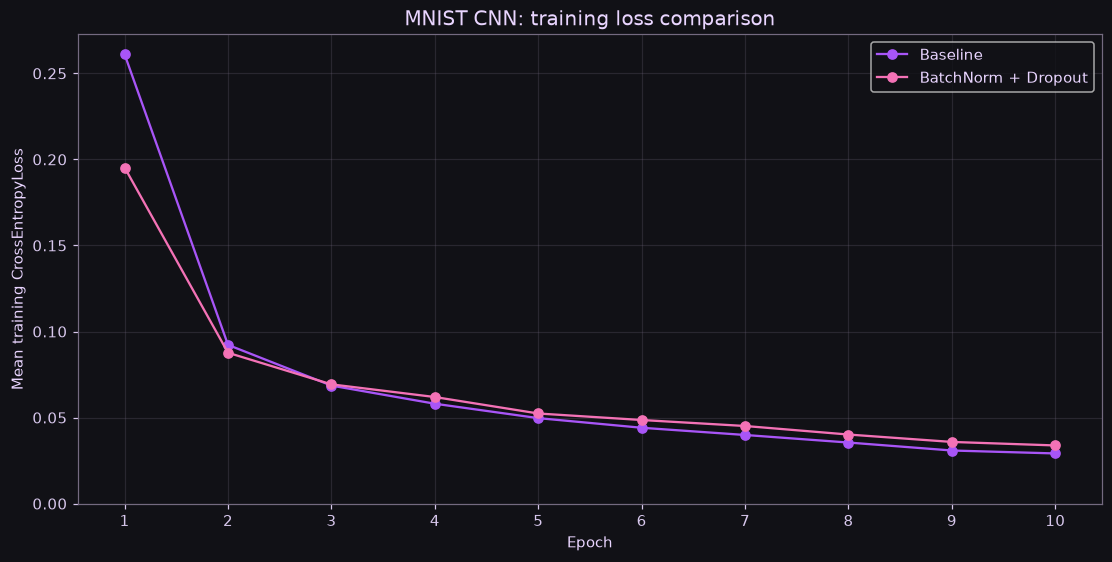

In [6]:
fig, ax = plt.subplots(layout="constrained")
for (name, history), color in zip(histories.items(), COLORS, strict=False):
    ax.plot(history["epoch"].to_numpy(), history["train loss"].to_numpy(),
            label=name, color=color, marker="o")
ax.set(title="MNIST CNN: training loss comparison", xlabel="Epoch", ylabel="Mean training CrossEntropyLoss")
ax.set_xticks(range(1, EPOCHS + 1))
ax.set_ylim(bottom=0)
ax.grid(True)
ax.set_axisbelow(True)
ax.legend()
fig.savefig(LOSS_PLOT_PATH, dpi=160, facecolor=fig.get_facecolor())
plt.show()


## <span style="color: #a855f7">Test accuracy and loss</span>

<span style="color: #a855f7">обидві моделі оцінюються на всіх 10000 test-зображень після завершення 10 епох, eval вимикає Dropout і перемикає BatchNorm на накопичені статистики, inference_mode вимикає обчислення градієнтів, Accuracy - частка правильних прогнозів, Loss - середній CrossEntropyLoss за всіма test-зображеннями, test не використовується для навчання або вибору епохи</span>

In [7]:
def evaluate_model(network, loader):
    network.eval()
    total_loss = 0.0
    correct = 0
    samples_seen = 0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    with torch.inference_mode():
        for images, labels in loader:
            logits = network(images)
            total_loss += criterion(logits, labels).item()
            correct += int((logits.argmax(dim=1) == labels).sum().item())
            samples_seen += images.size(0)
    return {"Accuracy": correct / samples_seen, "Loss": total_loss / samples_seen}


metrics = {name: evaluate_model(network, test_loader) for name, network in models.items()}
comparison = pd.DataFrame([
    {"configuration": name, **values,
     "note": "Original model" if name == "Baseline" else "BatchNorm + Dropout + gradient clipping (1.0)"}
    for name, values in metrics.items()
])
colorize(comparison.round(6), index=False)


configuration,Accuracy,Loss,note
Baseline,0.9796,0.067547,Original model
BatchNorm + Dropout,0.9804,0.064935,BatchNorm + Dropout + gradient clipping (1.0)


## <span style="color: #a855f7">Results interpretation</span>

<span style="color: #a855f7">підсумок порівняння нижче обчислюється з тестових метрик і діагностики градієнтів, показує зміну Accuracy та Loss, частоту спрацювання clipping на початку і в кінці навчання, перевірена межа градієнтів підтверджує роботу clipping, результат стосується цих двох конфігурацій при seed=42 і не відокремлює вплив BatchNorm, Dropout та clipping</span>

In [8]:
baseline_metrics = metrics["Baseline"]
regularized_metrics = metrics["BatchNorm + Dropout"]
accuracy_change = regularized_metrics["Accuracy"] - baseline_metrics["Accuracy"]
loss_change = regularized_metrics["Loss"] - baseline_metrics["Loss"]
correct_change = round(accuracy_change * len(test_dataset))
clipping_history = histories["BatchNorm + Dropout"]
clipped_count = int(clipping_history["clipped batches"].sum())
observed_max_norm = float(clipping_history["max norm after"].max())
first_clip_rate = float(clipping_history["clipped batches"].iloc[0] / clipping_history["batches"].iloc[0])
last_clip_rate = float(clipping_history["clipped batches"].iloc[-1] / clipping_history["batches"].iloc[-1])
quality_result = (
    "The regularized configuration improved both test metrics on this run"
    if accuracy_change > 0 and loss_change < 0
    else "The regularized configuration did not improve both test metrics on this run"
)
conclusions = [
    f'{quality_result}, accuracy change: {accuracy_change * 100:+.2f} percentage points ({correct_change:+d} correct predictions), test loss change: {loss_change:+.6f}',
    f'Gradient clipping affected {clipped_count} batches, the clipped share changed from {first_clip_rate:.2%} in the first epoch to {last_clip_rate:.2%} in the last epoch',
    f'The maximum observed gradient norm after clipping was {observed_max_norm:.6f}, within the {MAX_GRAD_NORM:.1f} limit with float32 tolerance',
    f'Both models completed all {EPOCHS} epochs with finite losses and gradients, the baseline also trained without numerical instability',
    'The test comparison measures the combined configuration, it does not establish which individual component caused the quality change',
]
display(HTML('<ul style="color: #a855f7">' + ''.join(f"<li>{escape(item)}</li>" for item in conclusions) + '</ul>'))
